# 🛢️ OilTankSight-AI: Model Performance & Results Dashboard
Interactive presentation dashboard displaying **test-set benchmark metrics**, **analytical evaluation charts**, **annotated satellite detection tiles**, and **training progression**.

In [13]:
# Interactive Code Toggle: Click to hide or show raw code cells
from IPython.display import HTML, display

display(HTML("""
<style>
.code-toggle-btn {
    background: linear-gradient(135deg, #00d4ff 0%, #0077ff 100%);
    color: white;
    border: none;
    padding: 10px 20px;
    font-size: 14px;
    font-weight: 600;
    border-radius: 6px;
    cursor: pointer;
    margin: 8px 0;
}
</style>
<button class='code-toggle-btn' onclick="
    const inputs = document.querySelectorAll('.jp-InputArea, .input');
    inputs.forEach(el => el.style.display = (el.style.display === 'none') ? '' : 'none');
">👁️ Toggle Show / Hide Code Cells</button>
"""))

In [14]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, HTML

# Paths to artifacts
eval_dir = Path("results/eval")
runs_train_dir = Path("runs/detect/results/training/oil_tank_yolov8m")
runs_val_dir = Path("runs/detect/results/eval/ultralytics_val/test")
vis_dir = eval_dir / "detection_visualizations"
lbl_dir = Path("data/processed/labels/test")

print("✅ Found evaluation directory:", eval_dir.resolve())
print("✅ Found training artifacts:", runs_train_dir.resolve())
print("✅ Found validation artifacts:", runs_val_dir.resolve())

✅ Found evaluation directory: /home/archit/Documents/Antigravity/OilTankSight-AI/results/eval
✅ Found training artifacts: /home/archit/Documents/Antigravity/OilTankSight-AI/runs/detect/results/training/oil_tank_yolov8m
✅ Found validation artifacts: /home/archit/Documents/Antigravity/OilTankSight-AI/runs/detect/results/eval/ultralytics_val/test


## 1. Quantitative Benchmark Metrics (Unseen Test Set)
Official benchmark numbers evaluated strictly on the **held-out Airbus test set**.

In [15]:
with open(eval_dir / "eval_summary.json") as f:
    summary = json.load(f)

# Overall metrics formatted table
metrics_df = pd.DataFrame([summary["metrics"]]).T.rename(columns={0: "Score"})
display(HTML("<h3>Overall Performance Summary</h3>"))
display(metrics_df)

# Detection counts
counts_df = pd.DataFrame([summary["counts"]]).T.rename(columns={0: "Count"})
display(HTML("<h3>Detection Counts</h3>"))
display(counts_df)

# Size stratified breakdown
size_df = pd.DataFrame(summary["size_stratified"]).T
display(HTML("<h3>Size-Stratified Performance (Tank Diameter Buckets)</h3>"))
display(size_df)

,Score
precision,0.7784
recall,0.8458
f1,0.8107
mAP_50,0.9218
mAP_50_95,0.6372
AUC_PR,0.7938


,Count
TP,1865
FP,531
FN,340


,gt_count,recall,mAP50
XS (<20px),1148.0,0.740,0.508
S (20-40px),791.0,0.952,0.818
M (40-70px),229.0,0.991,0.941
L (70-110px),37.0,0.946,0.808
XL (>110px),0.0,0.000,0.000


## 2. Evaluation Analysis Charts (`results/eval`)
In-depth analytical plots: Confusion matrix, Precision-Recall curve with AUC, size analysis, and failure mode breakdown.

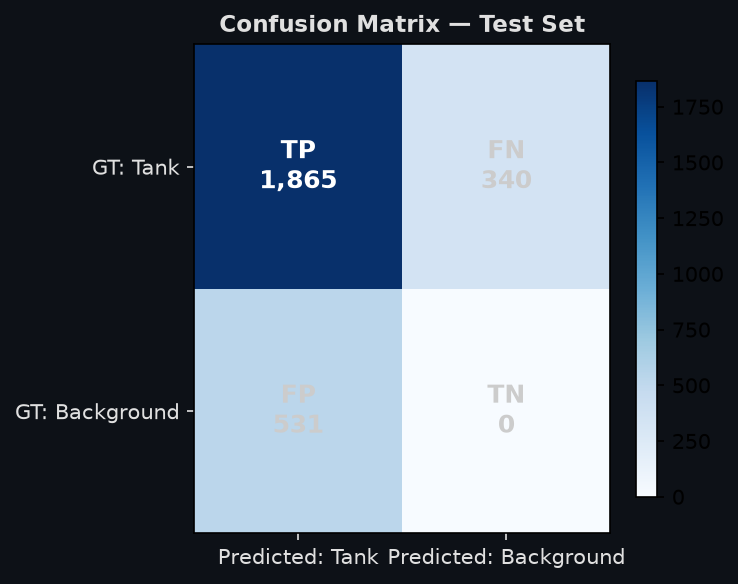

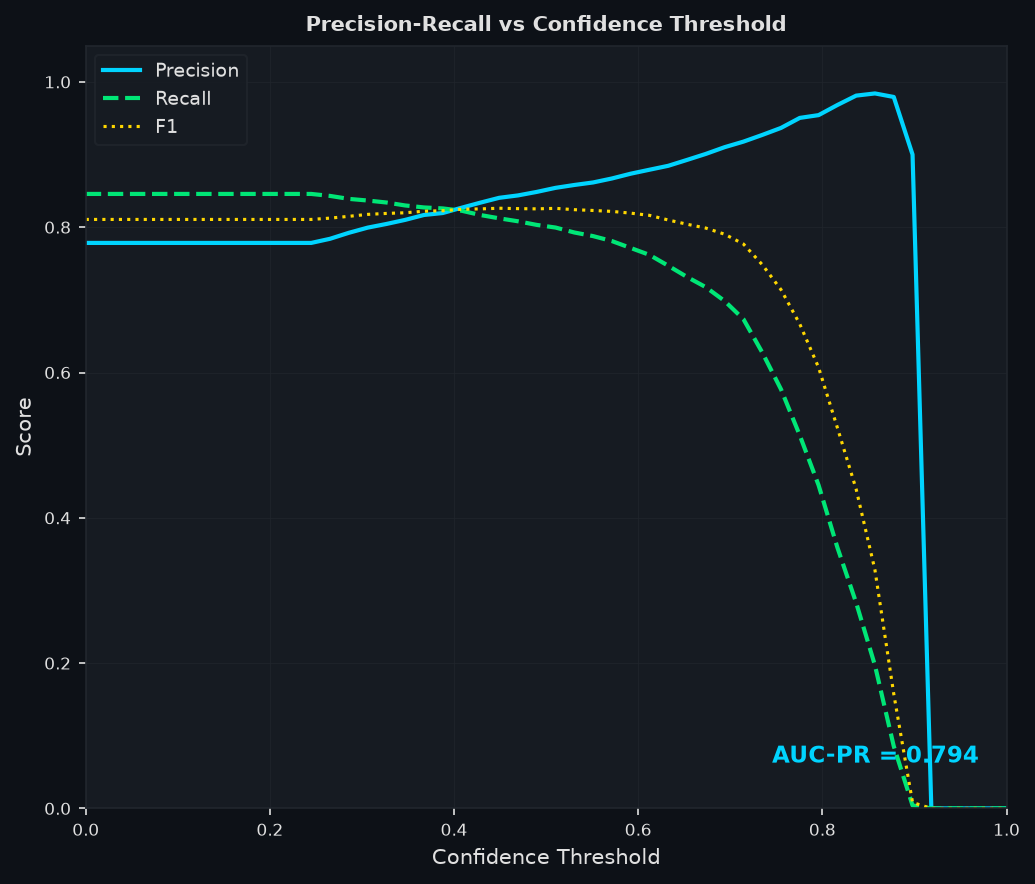

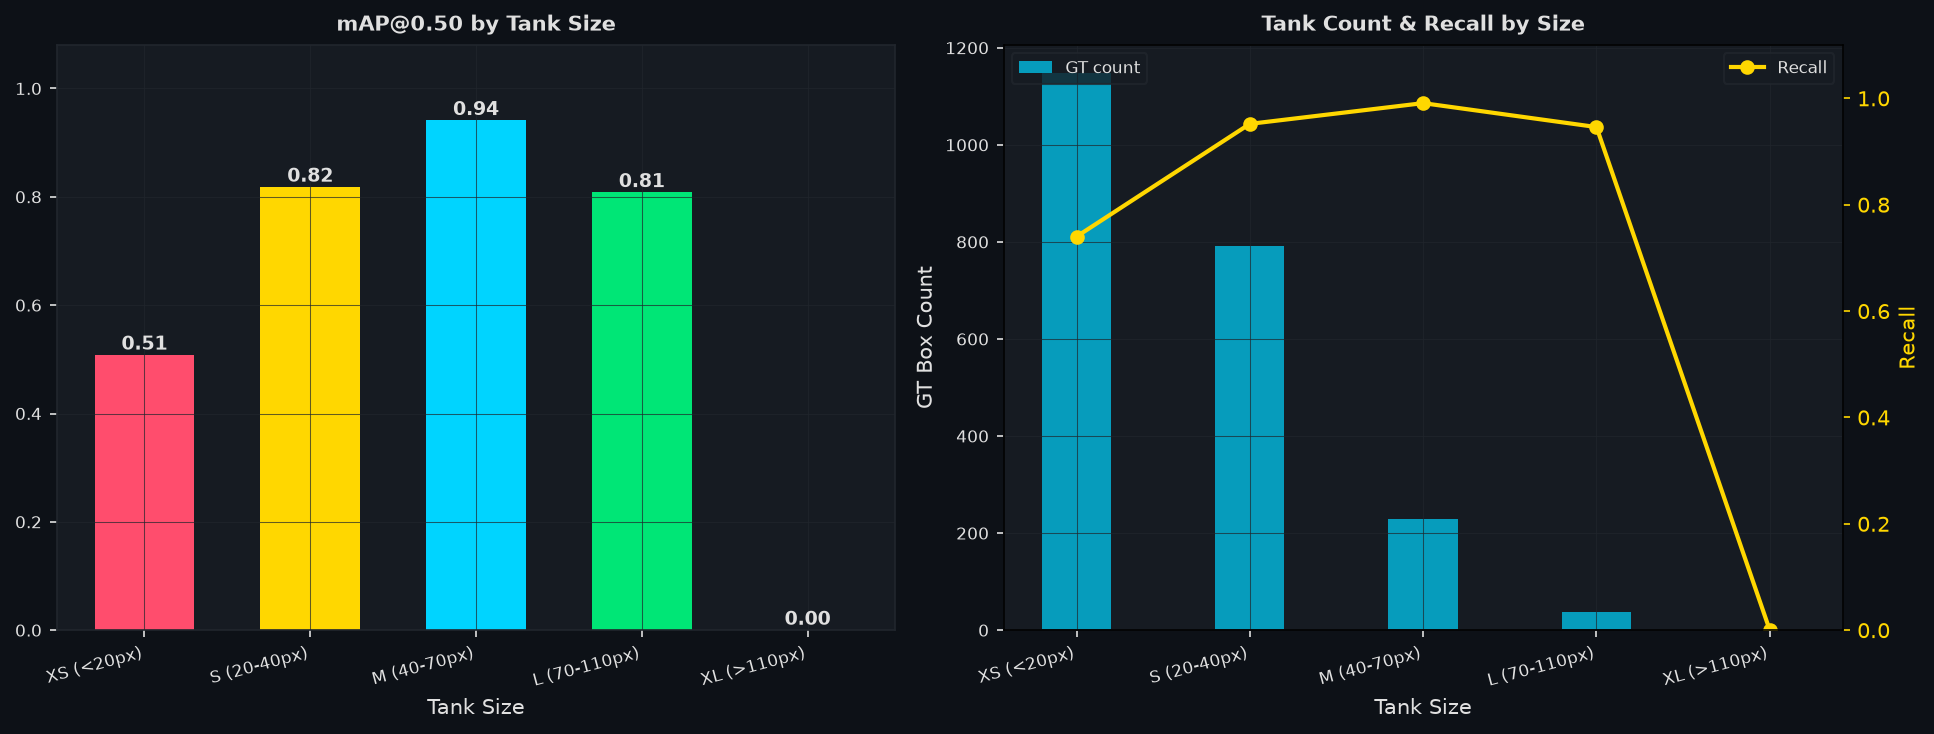

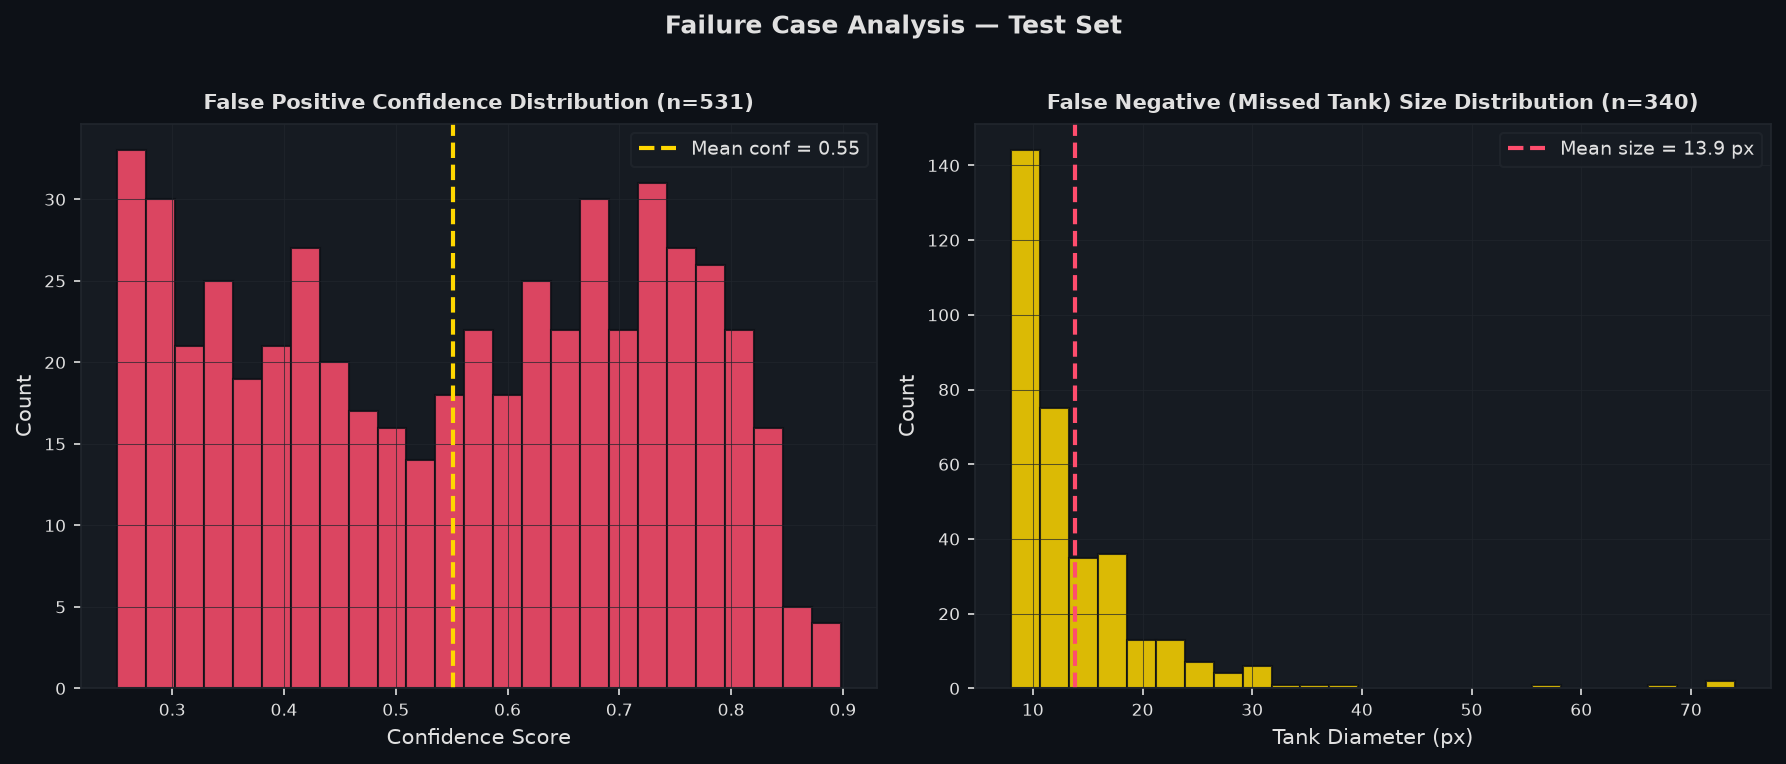

In [16]:
plots = [
    ("Confusion Matrix", eval_dir / "confusion_matrix.png"),
    ("Precision-Recall Curve (AUC = 0.794)", eval_dir / "pr_curve.png"),
    ("Size-Stratified Performance Analysis", eval_dir / "size_analysis.png"),
    ("False Positive & False Negative Failure Analysis", eval_dir / "failure_analysis.png"),
]

for title, path in plots:
    if path.exists():
        display(HTML(f"<h4>{title}</h4>"))
        display(Image(filename=str(path), width=850))
    else:
        print(f"File not found: {path}")

## 3. Qualitative Detections (High-Density Test Tiles)
High-resolution sample test tiles showing:
- 🟢 **Green Circles**: Ground Truth annotations
- 🔵 **Cyan Boxes**: YOLOv8 Detections with confidence scores

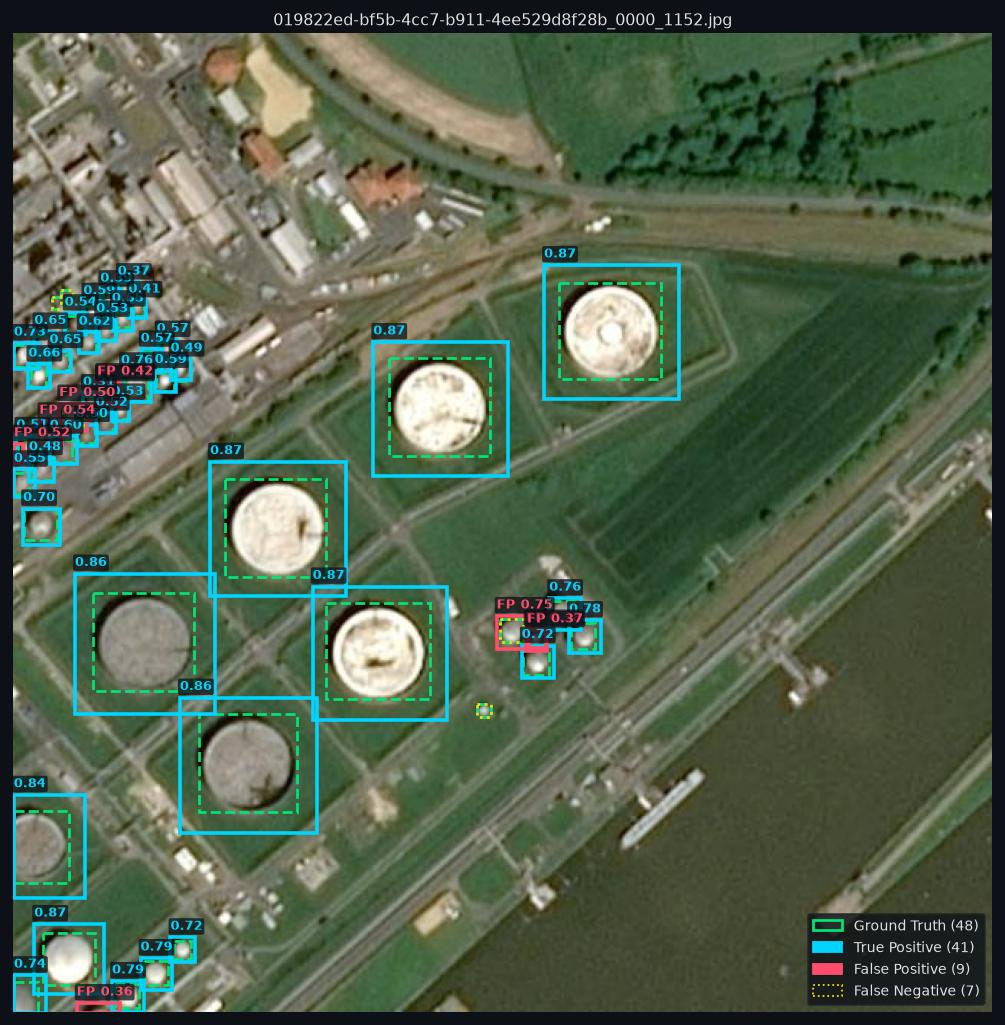

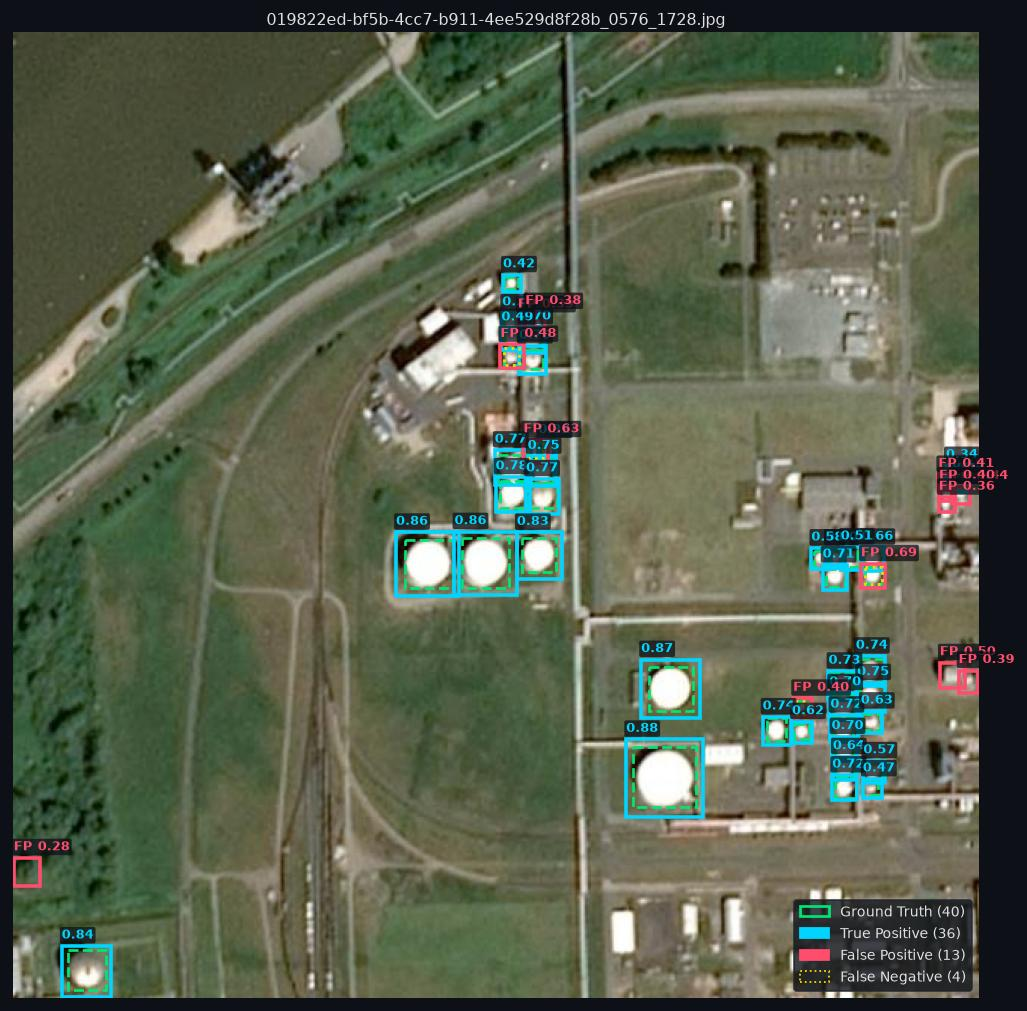

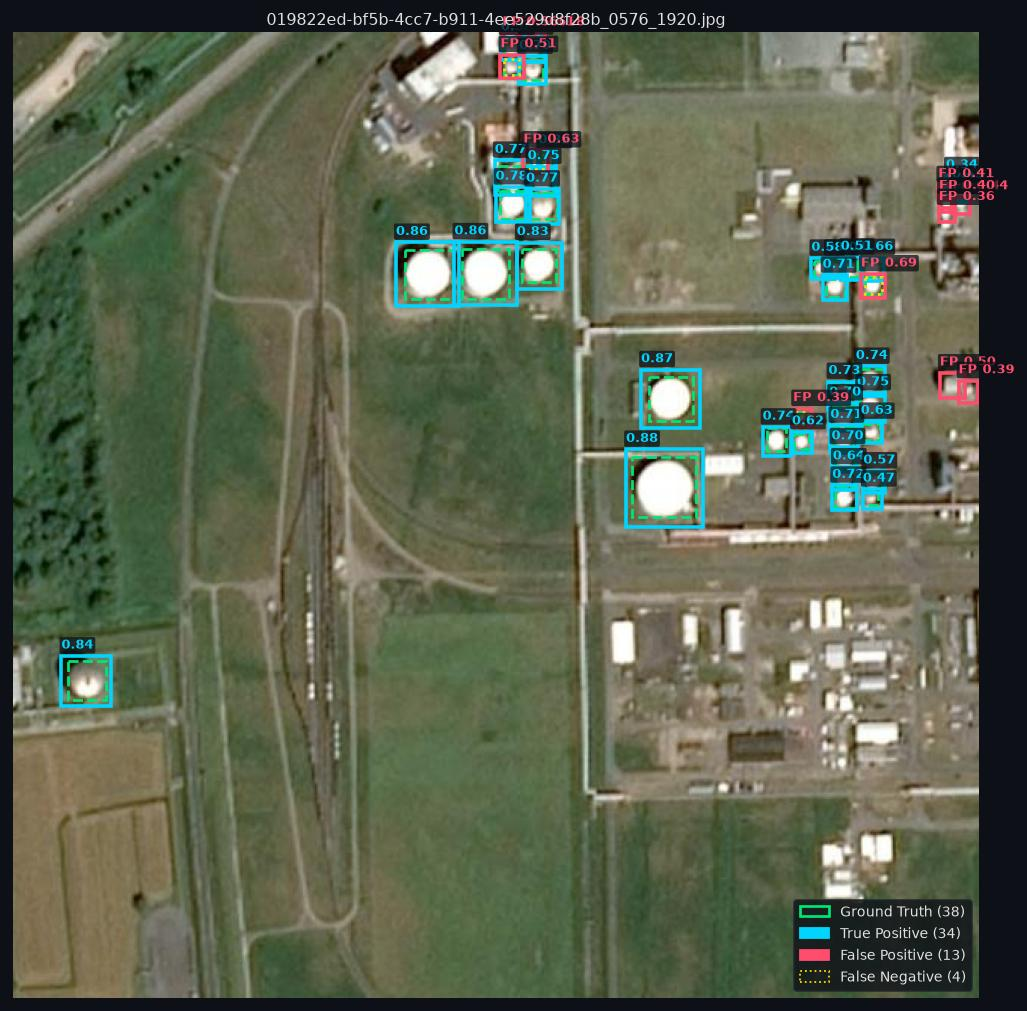

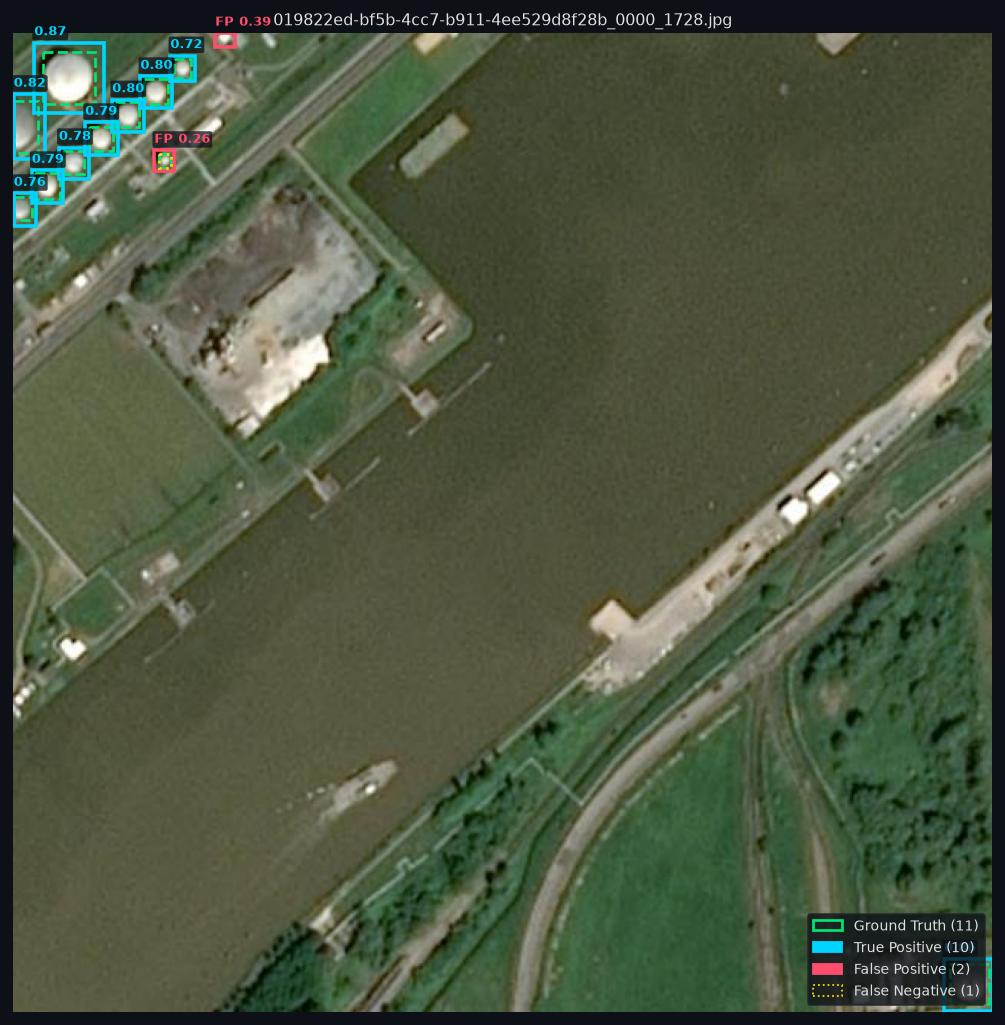

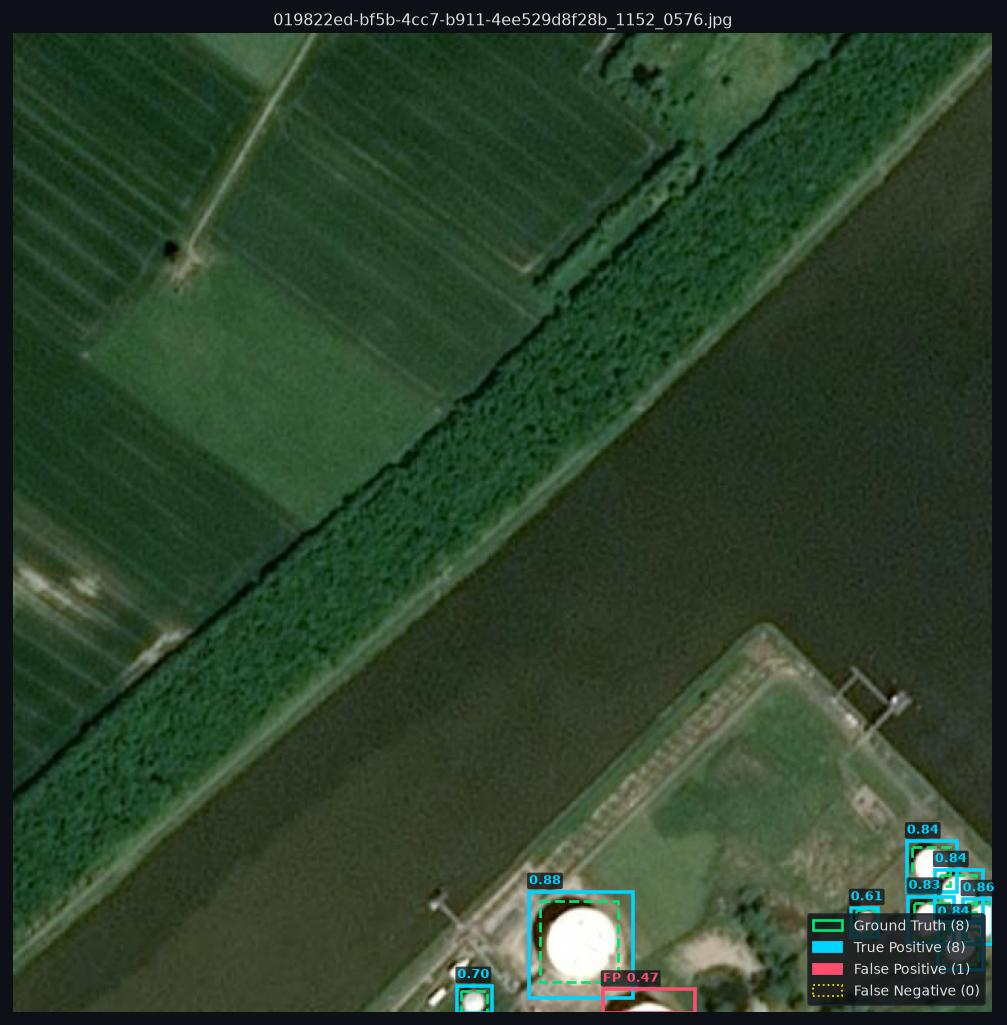

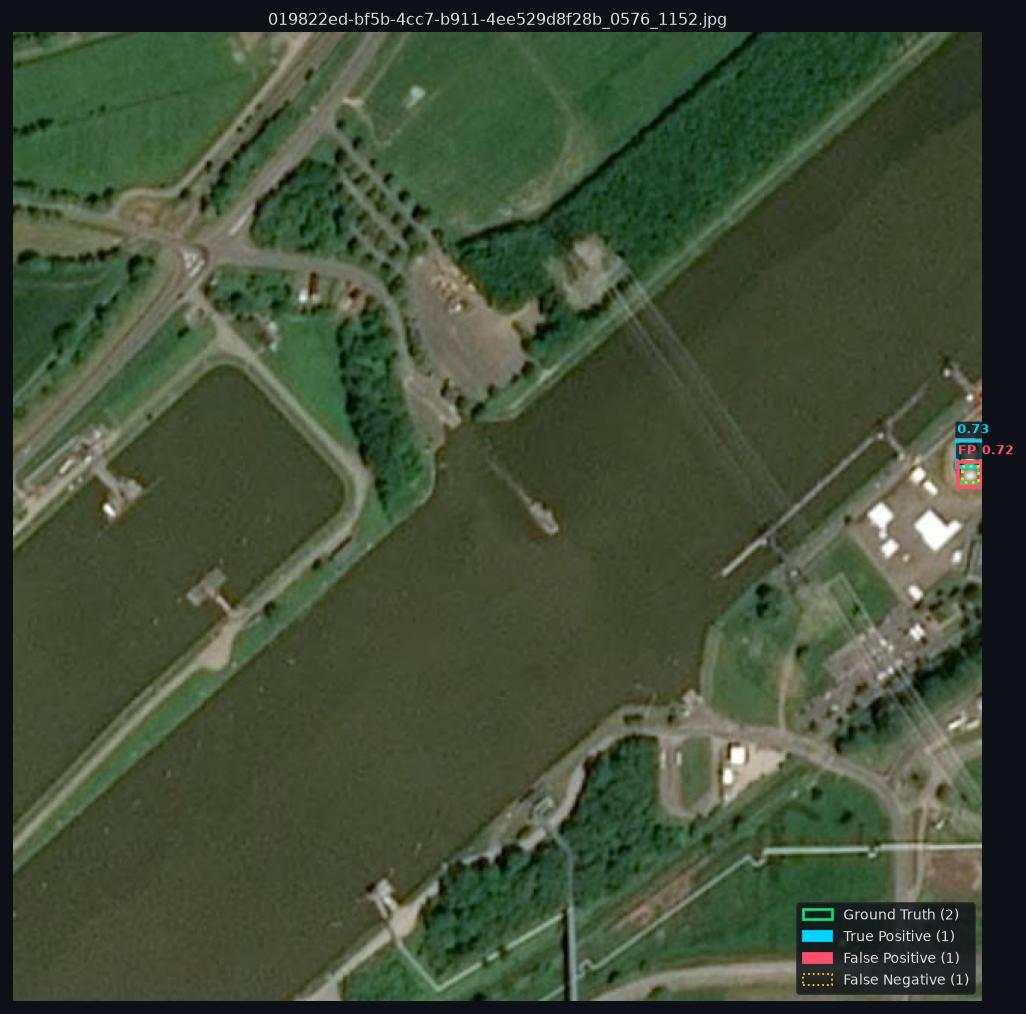

In [17]:
# Filter to showcase tiles that actually contain oil storage tanks
active_tiles = []
for p in sorted(vis_dir.glob("*_eval.jpg")):
    stem = p.name.replace("_eval.jpg", "")
    lbl_file = lbl_dir / f"{stem}.txt"
    count = 0
    if lbl_file.exists():
        with open(lbl_file) as f:
            count = len([l for l in f if l.strip()])
    if count > 0:
        active_tiles.append((p, count))

# Sort by number of tanks descending
active_tiles.sort(key=lambda x: x[1], reverse=True)
sample_images = active_tiles[:6]

display(HTML(f"<p>Displaying <b>{len(sample_images)}</b> high-density test tiles with real detections:</p>"))

for img_path, tank_count in sample_images:
    display(HTML(f"<b>Test Tile:</b> <code>{img_path.name}</code> &nbsp; | &nbsp; <b>Ground Truth Tanks:</b> <code>{tank_count}</code>"))
    display(Image(filename=str(img_path), width=750))

## 4. Training Progression & Augmentations (`runs/detect`)
Training history and convergence across 100 epochs.

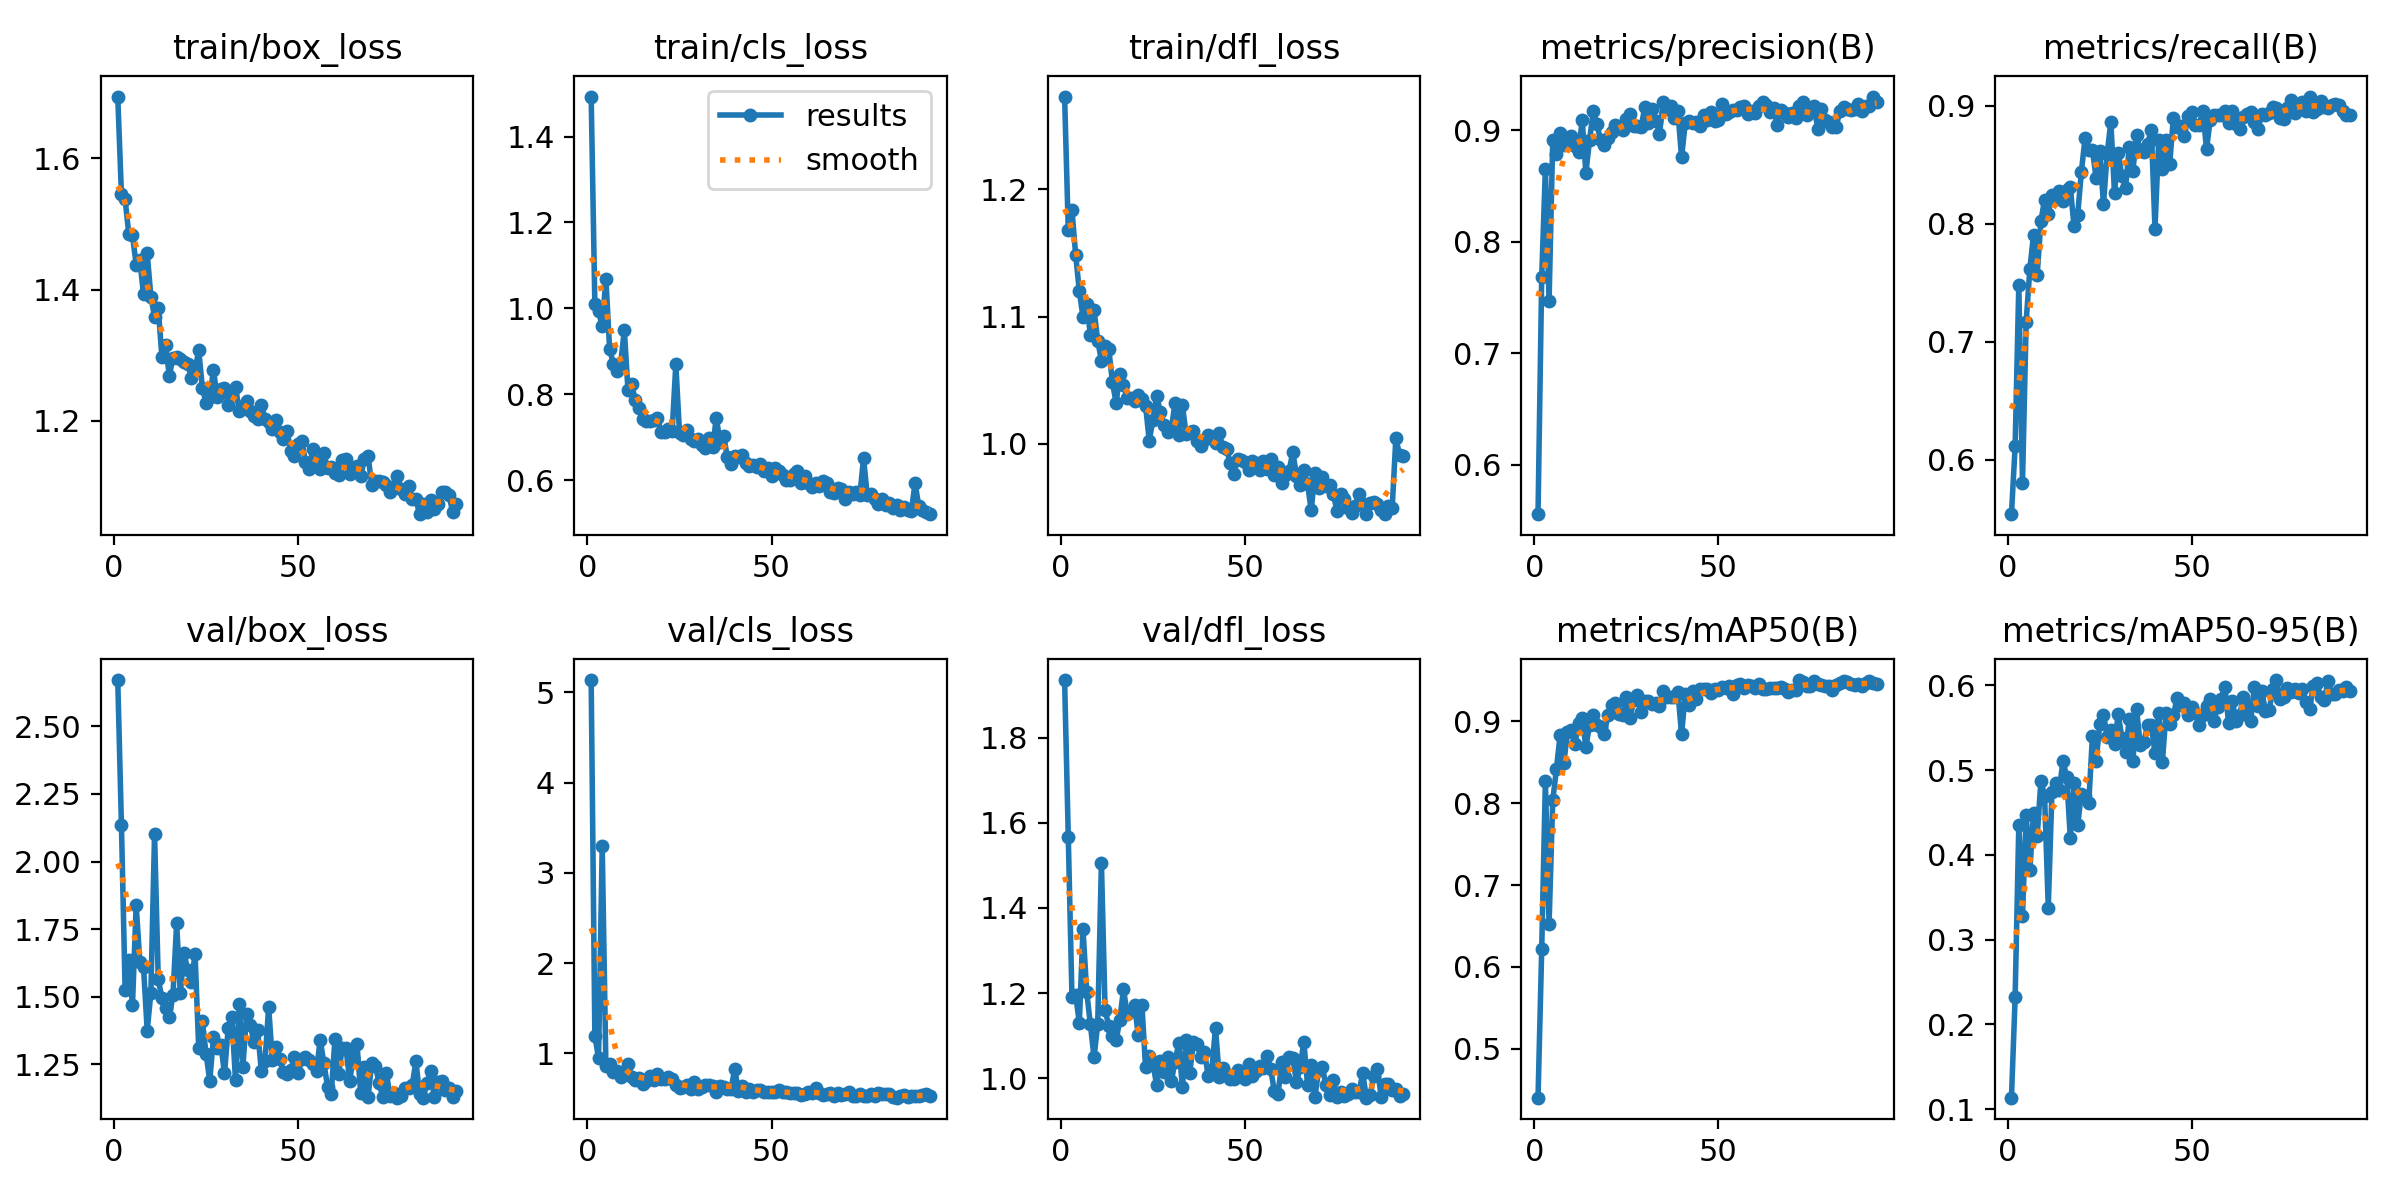

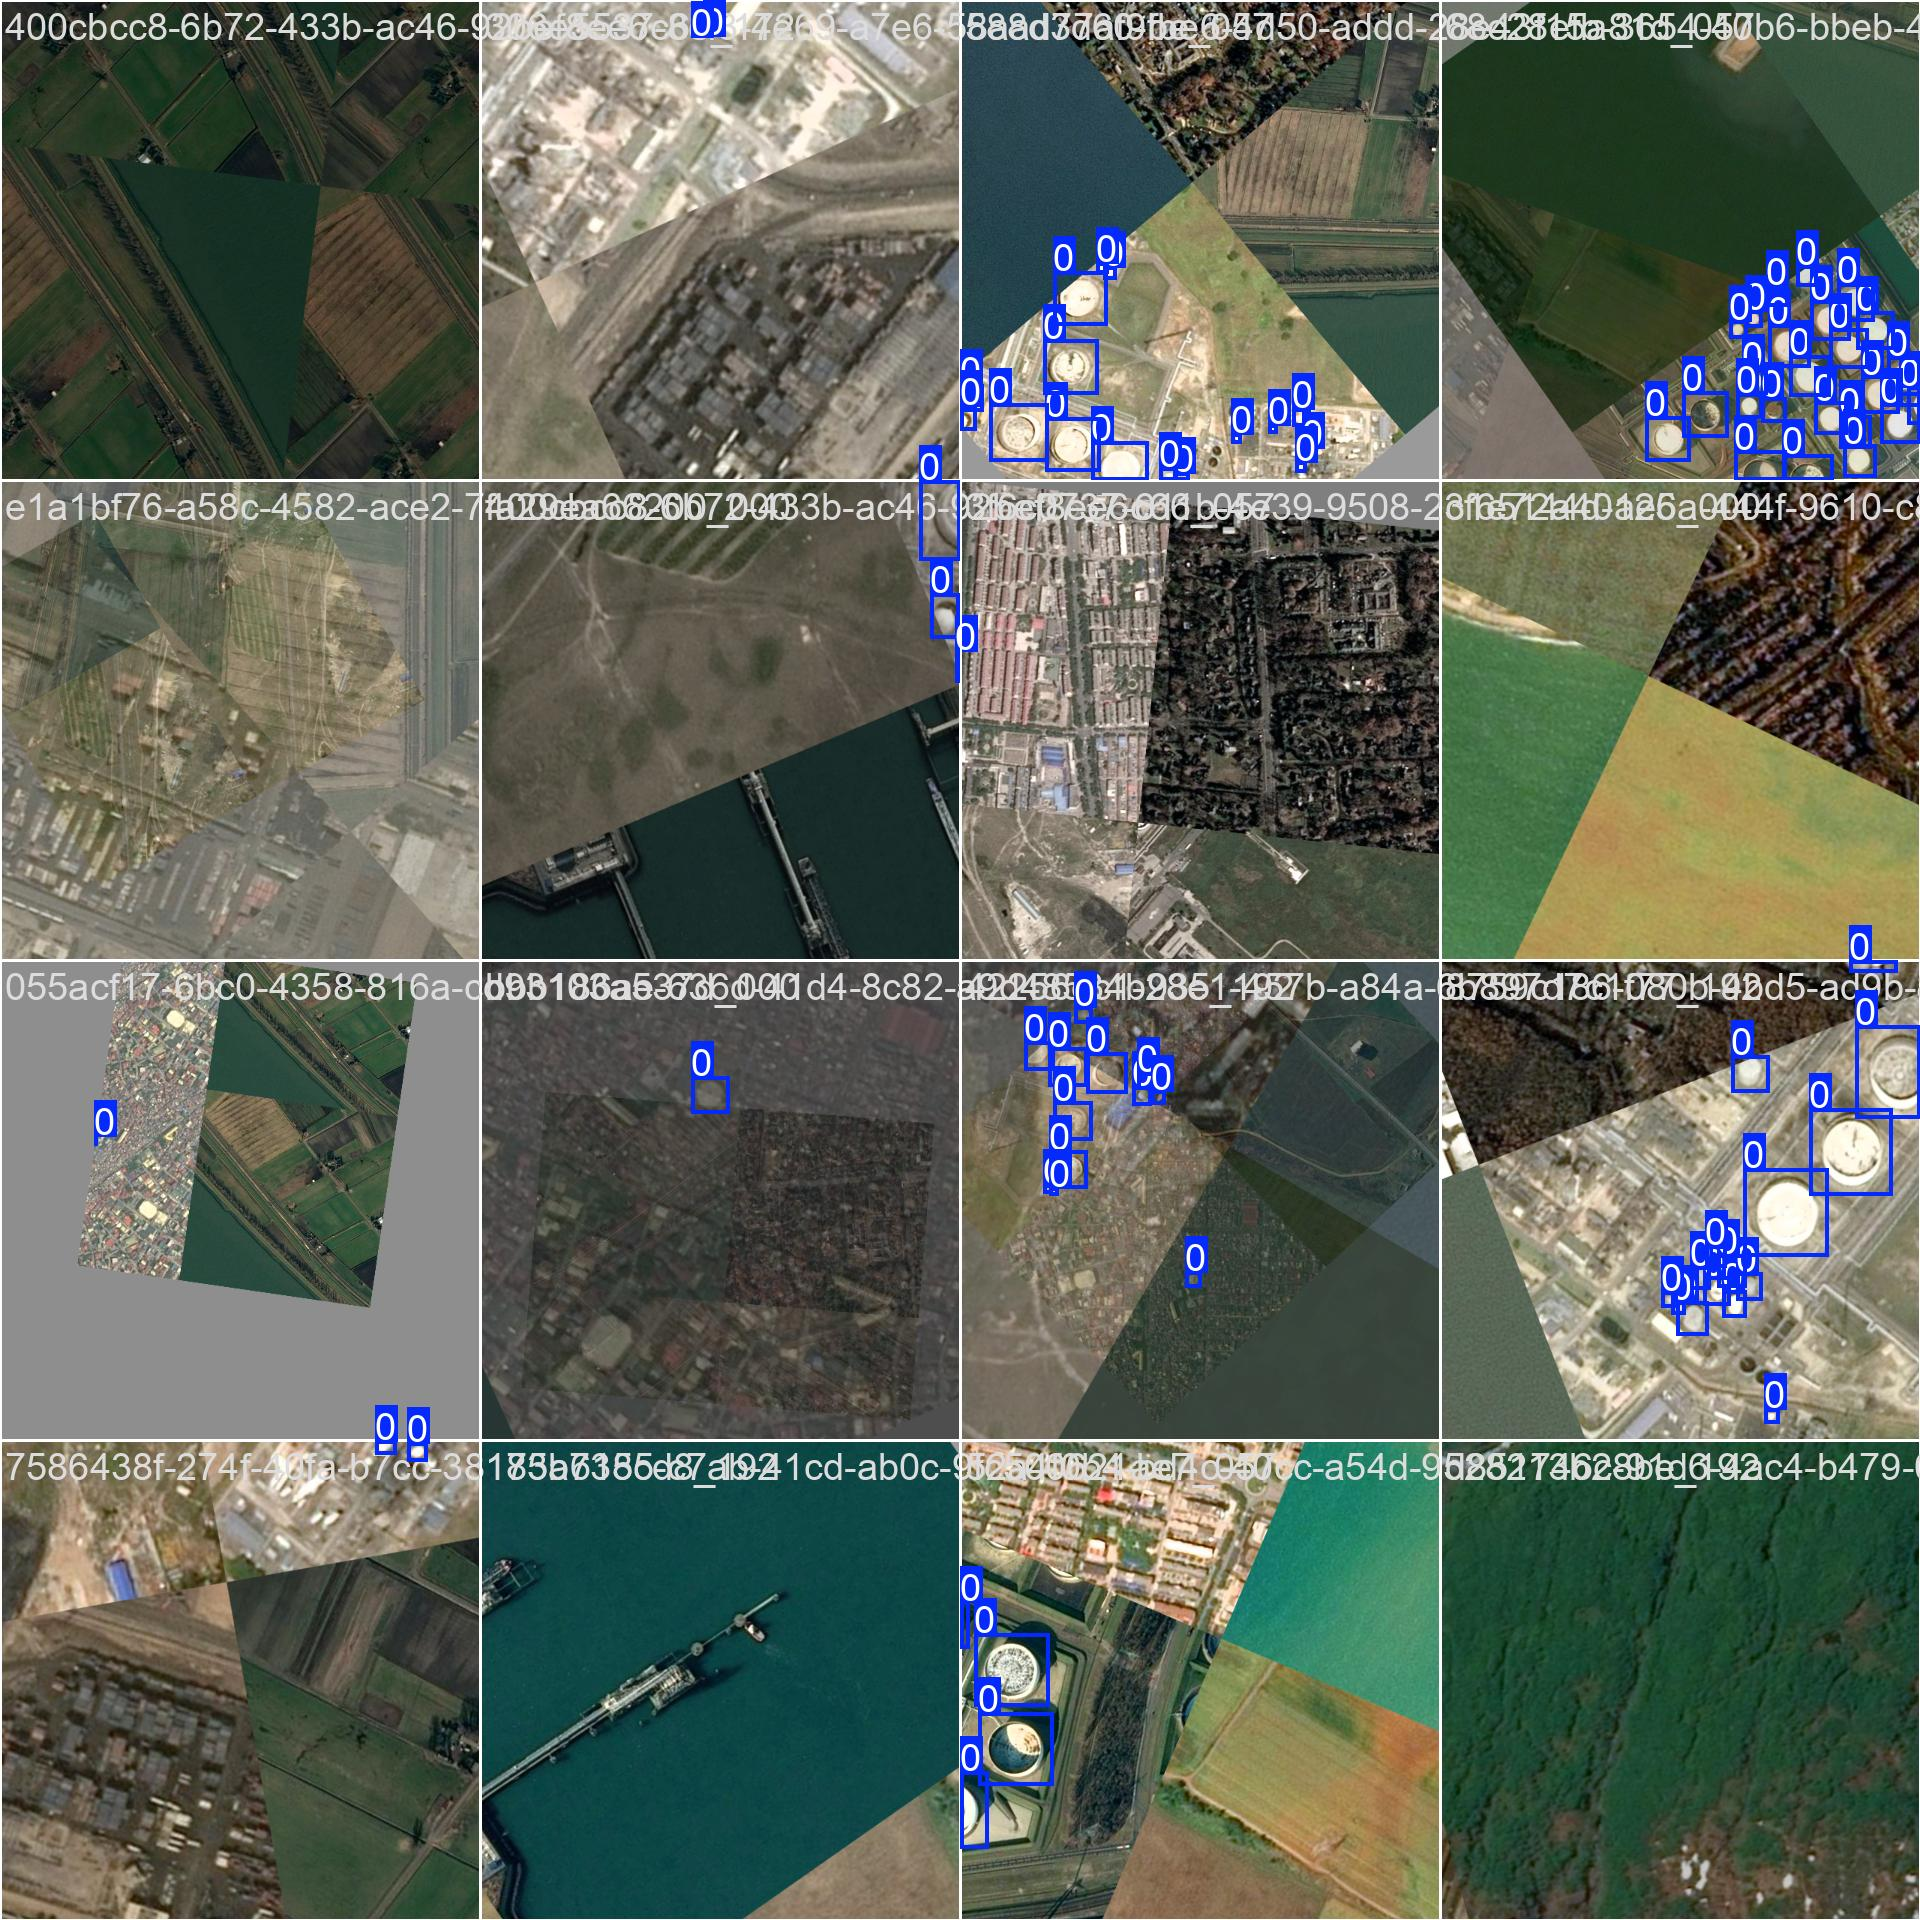

In [18]:
if (runs_train_dir / "results.png").exists():
    display(HTML("<h4>Training & Validation Loss / mAP Progression</h4>"))
    display(Image(filename=str(runs_train_dir / "results.png"), width=950))

if (runs_train_dir / "train_batch0.jpg").exists():
    display(HTML("<h4>Mosaic Data Augmentation (Training Batch 0)</h4>"))
    display(Image(filename=str(runs_train_dir / "train_batch0.jpg"), width=900))